In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,Deep neural networks are powerful black-box pr...,0.3467,0.0483,0.1653,0.8483,0.8210,0.8345,3,8,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We propose a novel spatiotemporal convolutiona...,0.3192,0.0752,0.1696,0.8503,0.8390,0.8446,2,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,In this paper we propose a process calculus fo...,0.1440,0.0413,0.0874,0.7817,0.8436,0.8115,4,2,3,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


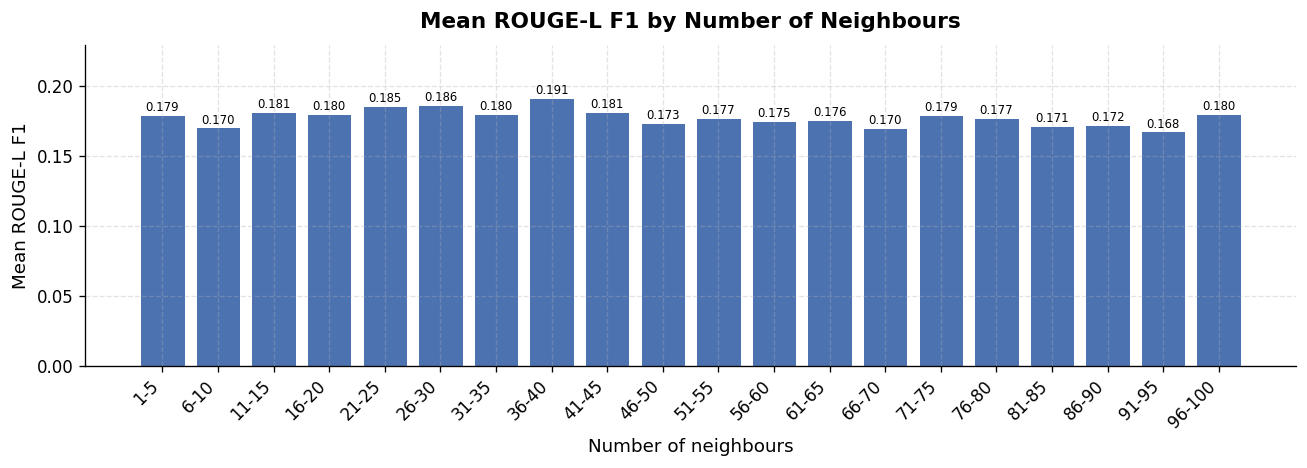

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

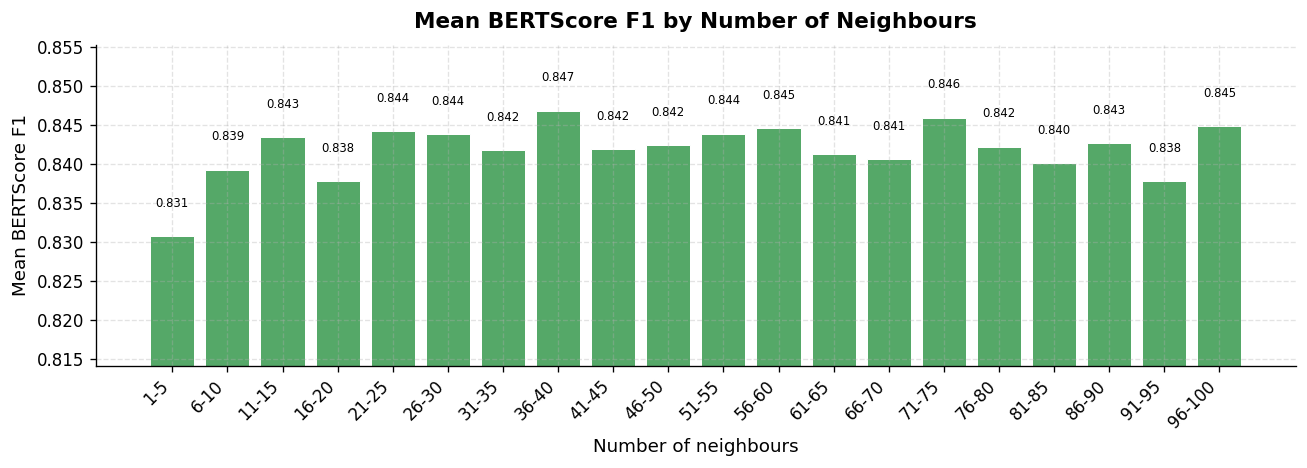

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

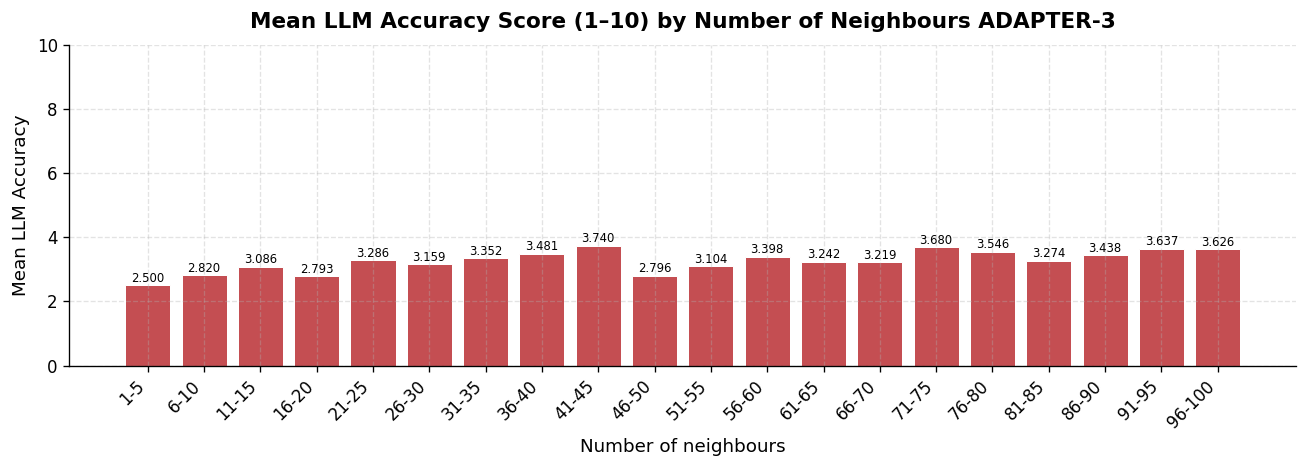

3.28994708994709
3.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

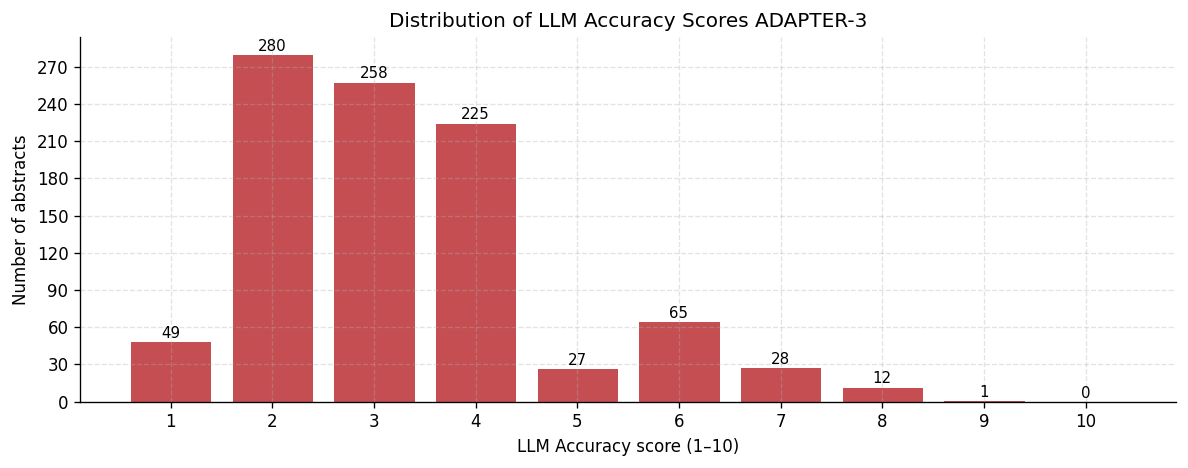

llm_accuracy
1      49
2     280
3     258
4     225
5      27
6      65
7      28
8      12
9       1
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

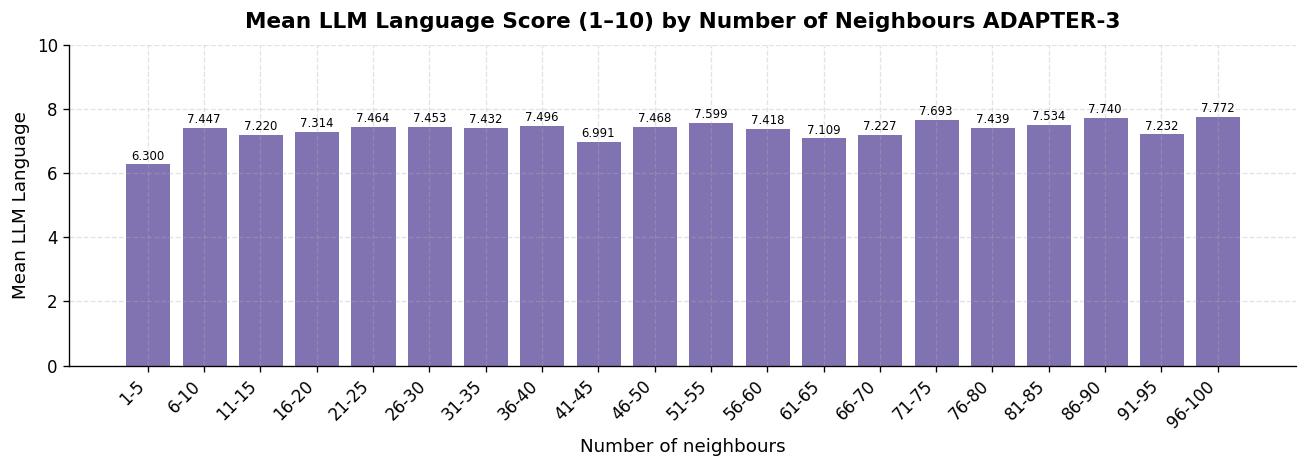

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

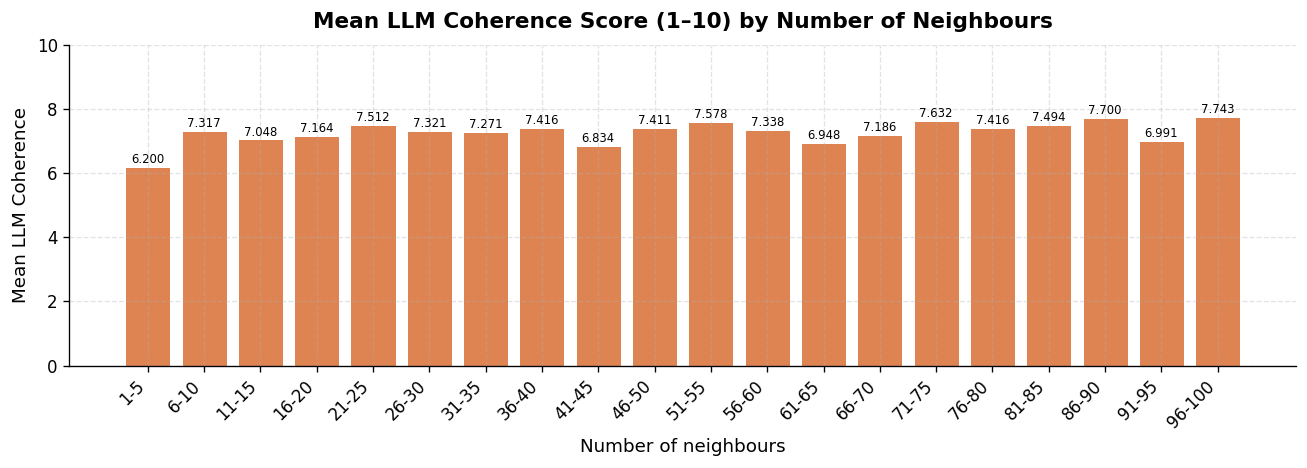

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

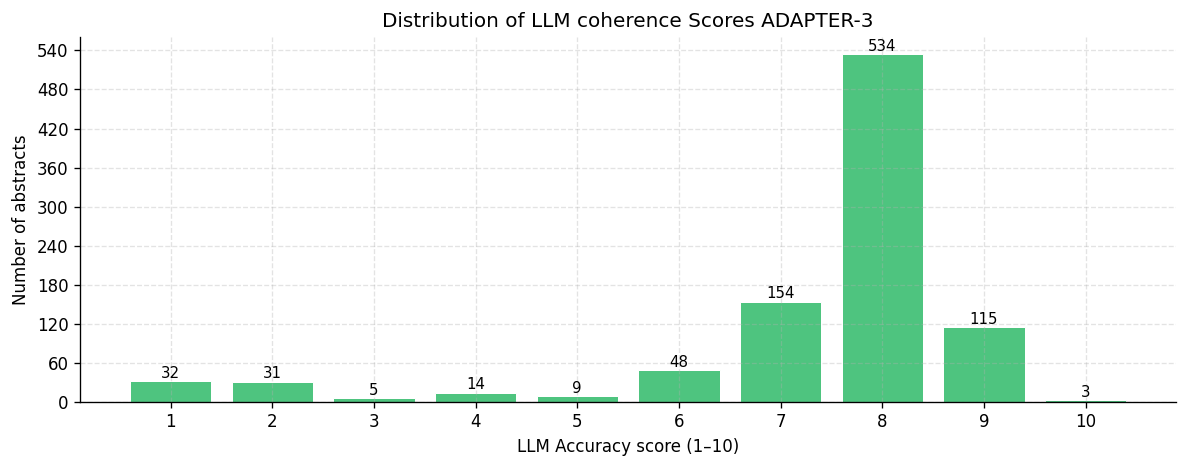

llm_coherence
1      32
2      31
3       5
4      14
5       9
6      48
7     154
8     534
9     115
10      3
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [13]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 63 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      3.2899
Mean llm_accuracy (excluding 1,2): 3.3492


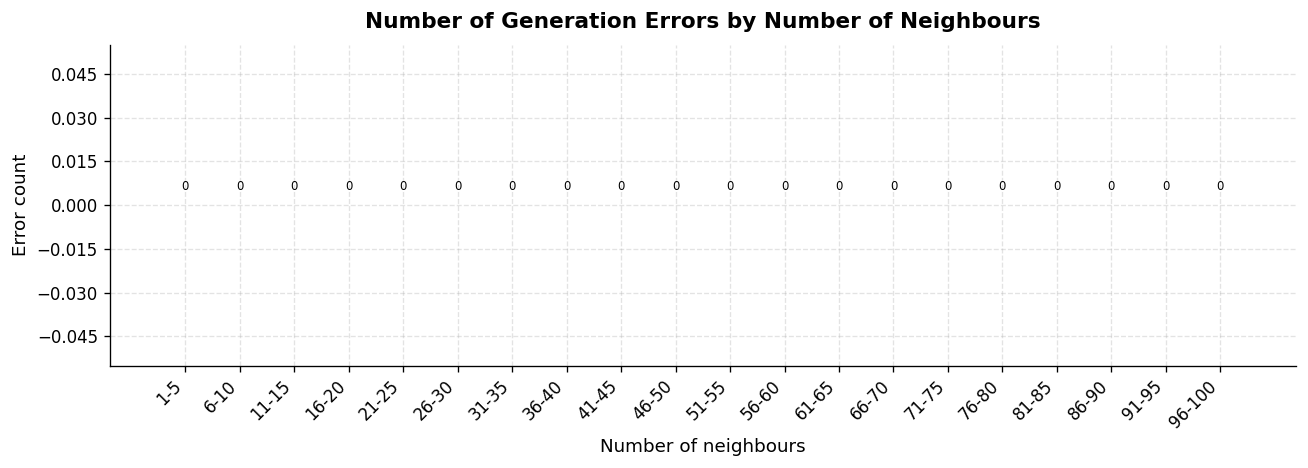

In [10]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [14]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_53959/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,96375,"Deep learning has achieved remarkable success in diverse applications; however, its use in solving partial differential equations (PDEs) has emerged only recently. Here, we present an overview of physics-informed neural networks (PINNs), which embed a PDE into the loss of the neural network using automatic differentiation. The PINN algorithm is simple, and it can be applied to different types of PDEs, including integro-differential equations, fractional PDEs, and stochastic PDEs. Moreover, PINNs solve inverse problems as easily as forward problems. We propose a new residual-based adaptive refinement (RAR) method to improve the training efficiency of PINNs. For pedagogical reasons, we compare the PINN algorithm to a standard finite element method. We also present a Python library for PINNs, DeepXDE, which is designed to serve both as an education tool to be used in the classroom as well as a research tool for solving problems in computational science and engineering. DeepXDE supports complex-geometry domains based on the technique of constructive solid geometry, and enables the user code to be compact, resembling closely the mathematical formulation. We introduce the usage of DeepXDE and its customizability, and we also demonstrate the capability of PINNs and the user-friendliness of DeepXDE for five different examples. More broadly, DeepXDE contributes to the more rapid development of the emerging Scientific Machine Learning field.",We propose a novel deep learning framework for solving partial differential equations (PDEs) in high dimensions. The proposed framework is based on a deep neural network (DNN) that is trained to solve a PDE using a set of input data. The DNN is trained using a loss function that is defined in terms of the PDE solution and the input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The proposed framework is able to solve PDEs in high dimensions because the DNN is able to learn the solution of the PDE using a small number of input data. The,1
1,72838,"We introduce Negative Sampling in Semi-Supervised Learning (NS3L), a simple, fast, easy to tune algorithm for semi-supervised learning (SSL). NS3L is motivated by the success of negative sampling/contrastive estimation. We demonstrate that adding the NS3L loss to state-of-the-art SSL algorithms, such as the Virtual Adversarial Training (VAT), significantly improves upon vanilla VAT and its variant, VAT with Entropy Minimization. By adding the NS3L loss to MixMatch, the current state-of-the-art approach on semi-supervised tasks, we observe significant improvements over vanilla MixMatch. We conduct extensive experiments on the CIFAR10, CIFAR100, SVHN and STL10 benchmark datasets.","Semi-supervised learning (SSL) has been shown to be effective in improving the performance of deep neural networks when labeled data is scarce. However, the current state-of-the-art SSL methods are not robust to adversarial examples. In this work, we propose a novel semi-supervised learning framework that is robust to adversarial

In [11]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_53959/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,169281,"Towards automated retinal screening, this paper makes an endeavor to simultaneously achieve pixel-level retinal lesion segmentation and image-level disease classification. Such a multi-task approach is crucial for accurate and clinically interpretable disease diagnosis. Prior art is insufficient due to three challenges, that is, lesions lacking objective boundaries, clinical importance of lesions irrelevant to their size, and the lack of one-to-one correspondence between lesion and disease classes. This paper attacks the three challenges in the context of diabetic retinopathy (DR) grading. We propose L-Net, a new variant of fully convolutional networks, with its expansive path re-designed to tackle the first challenge. A dual loss that leverages both semantic segmentation and image classification losses is devised to resolve the second challenge. We propose Side-Attention Net (SiAN) as our multi-task framework. Harnessing L-Net as a side-attention branch, SiAN simultaneously improves DR grading and interprets the decision with lesion maps. A set of 12K fundus images is manually segmented by 45 ophthalmologists for 8 DR-related lesions, resulting in 290K manual segments in total. Extensive experiments on this large-scale dataset show that our proposed approach surpasses the prior art for multiple tasks including lesion segmentation, lesion classification and DR grading.","In this paper, we propose a novel network architecture called Dual Attention Network (DANet) for semantic segmentation. DANet is designed to adaptively integrate local features with their global dependencies. Specifically, we append two types of attention modules on top of traditional dilated FCN, which model the semantic interdependencies in spatial and channel dimensions respectively. The position attention module selectively aggregates the features at each position by a weighted sum of the features at all positions. Similar features would be related to each other regardless of their distances. Meanwhile, the channel attention module selectively emphasizes interdependent channel maps by integrating associated features among all channel maps. We sum the outputs of the two attention modules to further improve feature representation which contributes to more precise segmentation results. We achieve new state-of-the-art segmentation performance on three challenging scene segmentation datasets, i.e., Cityscapes, PASCAL Context and COCO Stuff dataset. In particular, a Mean IoU score of 81.5% on Cityscapes test set is achieved without using coarse data.",1
1,88468,"We study the Proportional Response dynamic in exchange economies, where each player starts with some amount of money and a good. Every day, the players bring one unit of their good and submit bids on goods they like, each good gets allocated in proportion to the bid amounts, and each seller collects the bids received. Then every player updates the bids proportionally to the contribution of each good in their utility. This dynamic models a process of learning how to bid and has been studied in a series of papers on Fisher and production markets, but not in exchange economies. Our main results are as follows: - For linear utilities, the dynamic converges to market equilibrium utilities and allocations, while the bids and prices may cycle. We give a combinatorial characterization of limit cycles for prices and bids. - We introduce a lazy version of the dynamic, where players may save money for later, and show this converges in everything: utilities, allocations, and prices. - For CES utilities in the substitute range $[0,1)$, the dynamic converges for all parameters. This answers an open question about exchange economies with linear utilities, where tatonnement does not converge to market equilibria, and no natural process leading to equilibria was known. We also note that proportional response is a process where the players exchange goods

In [12]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


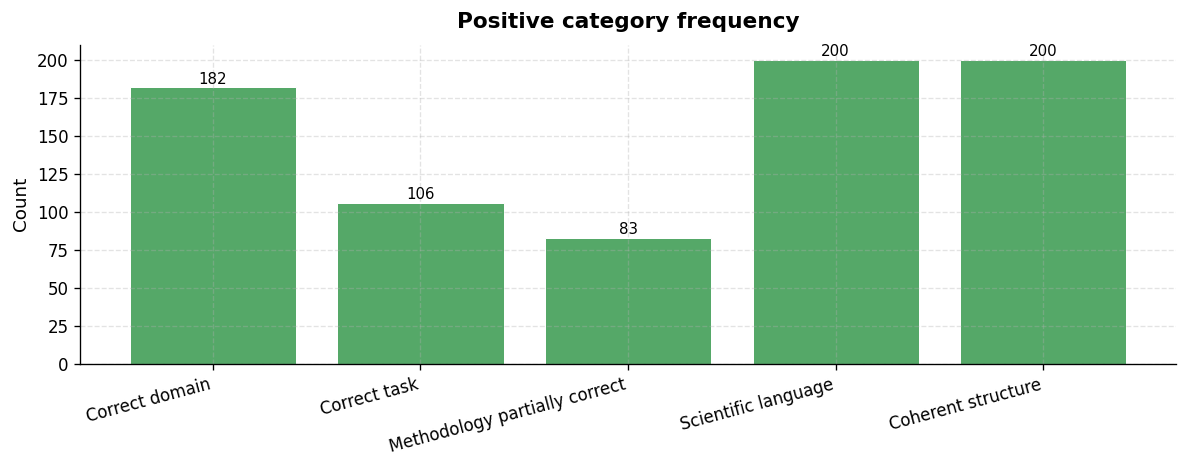

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()